# 2. Did the quiz actually help? (the A/B test)

This notebook answers the real questions a decision-maker asks:

1. How likely is it that the quiz is genuinely better?
2. How big is the improvement, and how sure are we?
3. What does it cost us if we're wrong?
4. Are there any side effects we should worry about?
5. Is it worth doing, and how should we roll it out?

We answer all five in everyday language, using a **Bayesian** approach. The
statistics are in the cells, but you can follow the whole story from the text.

## What does "Bayesian" mean here?

Imagine you're guessing how tall a stranger is. Before they stand up, you'd guess
"about average". Then they stand next to a doorway and clearly are tall — so you
**update** your guess. A Bayesian analysis is that idea, done with numbers: start
with what you believe, then update it as the evidence comes in.

- **Prior** — what we believed before seeing the experiment data.
- **Posterior** — our updated belief after seeing it. This is the answer.
- A **credible interval** is the range that most likely contains the true value.

We choose this approach because it speaks the language of decisions
("how likely is B better?", "what's the downside?") rather than the language of
p-values.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
sys.path.insert(0, "../src")
from scipy import stats

import analyze as az

DB = "../warehouse.duckdb"
primary = az.q(DB, "select * from mart_primary_metric").set_index("variant")
guard_df = az.q(DB, "select * from mart_guardrails").set_index("variant")
comm = az.q(DB, "select * from mart_commercial_inputs").set_index("variant")
rng = np.random.default_rng(az.ANALYSIS_SEED)
primary

,reached_selection_users,converted_users,conversion_rate
variant,,,
A,9870,3933.0,0.398480
B,10164,4386.0,0.431523


## Step 1 — What we believed beforehand (the prior)

Before this experiment we'd guess conversion is "somewhere around 40%" with a
generous amount of uncertainty. We express that as a gentle bell-shaped belief.
Being *weak* on purpose means the data, not our prior, drives the conclusion.

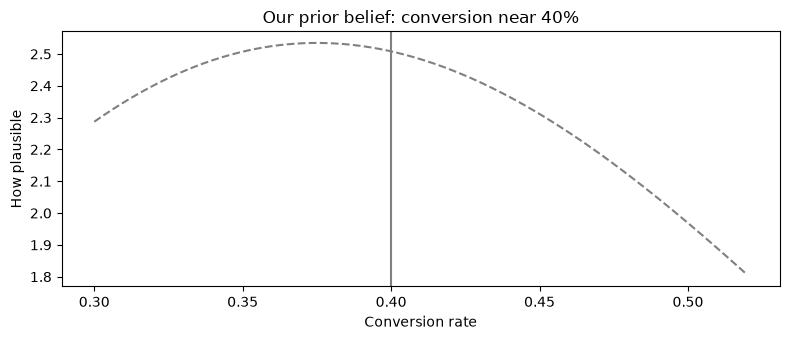

In [2]:
xs = np.linspace(0.30, 0.52, 500)
plt.figure(figsize=(8, 3.5))
plt.plot(xs, stats.beta.pdf(xs, az.PRIOR_A0, az.PRIOR_B0), color="grey", ls="--")
plt.axvline(az.PRIOR_A0 / (az.PRIOR_A0 + az.PRIOR_B0), color="grey")
plt.title(f"Our prior belief: conversion near {az.PRIOR_A0 / (az.PRIOR_A0 + az.PRIOR_B0):.0%}")
plt.xlabel("Conversion rate")
plt.ylabel("How plausible")
plt.tight_layout()
plt.show()

## Step 2 — Update the belief with the data (the posterior)

Now we show the model the real outcomes and let it update. The two coloured
curves are the updated beliefs for A and B.

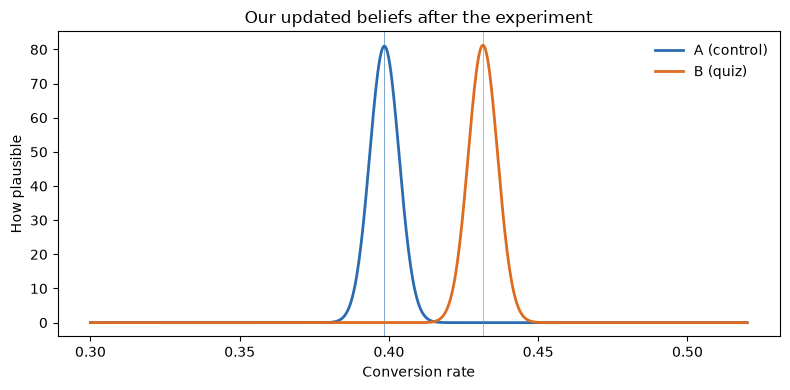

A: most likely 39.8%  (range 38.9% to 40.8%)
B: most likely 43.1%  (range 42.2% to 44.1%)


In [3]:
arm_a = az.summarize_arm(
    int(primary.loc["A", "converted_users"]),
    int(primary.loc["A", "reached_selection_users"]),
    rng,
    az.PRIOR_A0,
    az.PRIOR_B0,
)
arm_b = az.summarize_arm(
    int(primary.loc["B", "converted_users"]),
    int(primary.loc["B", "reached_selection_users"]),
    rng,
    az.PRIOR_A0,
    az.PRIOR_B0,
)

xs = np.linspace(0.30, 0.52, 600)
plt.figure(figsize=(8, 4))
for arm, color, name in [(arm_a, az.BLUE, "A (control)"), (arm_b, az.ORANGE, "B (quiz)")]:
    plt.plot(
        xs,
        stats.beta.pdf(xs, arm["posterior_alpha"], arm["posterior_beta"]),
        color=color,
        lw=2,
        label=name,
    )
    plt.axvline(arm["posterior_mean"], color=color, lw=0.7, alpha=0.6)
plt.title("Our updated beliefs after the experiment")
plt.xlabel("Conversion rate")
plt.ylabel("How plausible")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

print(
    f"A: most likely {arm_a['posterior_mean']:.1%}  (range {arm_a['credible_interval'][0]:.1%} to {arm_a['credible_interval'][1]:.1%})"
)
print(
    f"B: most likely {arm_b['posterior_mean']:.1%}  (range {arm_b['credible_interval'][0]:.1%} to {arm_b['credible_interval'][1]:.1%})"
)

**What this tells us.** The two curves are well separated — they barely overlap.
In plain terms: the data strongly points to B being the better version. If they
overlapped a lot, we couldn't tell.

## Step 3 — Turning beliefs into a decision

Now the numbers that a leader actually uses. In plain English:

- **P(B > A)** — the chance B is genuinely better.
- **Likely lift** — the size of the improvement, with a range.
- **Expected loss** — the average downside *if we pick the wrong one*.

In [4]:
decision = az.decision_outputs(arm_a["_draws"], arm_b["_draws"], arm_a["posterior_mean"])
print(f"Chance B is better than A:  {decision['prob_b_beats_a']:.4%}")
print(
    f"Likely improvement:         {decision['abs_lift_mean'] * 100:+.2f} percentage points "
    f"(range {decision['abs_lift_ci'][0] * 100:+.2f} to {decision['abs_lift_ci'][1] * 100:+.2f})"
)
print(f"Relative improvement:       {decision['rel_lift_mean']:.1%}")
print(
    f"Expected loss if we pick B: {decision['expected_loss_choosing_b'] * 100:.4f} percentage points"
)
print(
    f"Expected loss if we pick A: {decision['expected_loss_choosing_a'] * 100:.2f} percentage points"
)

Chance B is better than A:  100.0000%
Likely improvement:         +3.30 percentage points (range +1.94 to +4.67)
Relative improvement:       8.3%
Expected loss if we pick B: 0.0000 percentage points
Expected loss if we pick A: 3.30 percentage points


**What this tells us.** B is better with near-certainty, the improvement is
roughly **+3 percentage points**, and the *cost of being wrong* is essentially
zero. If anything, the risk is in sticking with A.

## Step 4 — A second opinion (the classic test)

Many teams are more familiar with the classic "is this difference statistically
significant?" test. We run it too — if two very different methods agree, that's
reassuring. If they disagreed, we'd dig in.

In [5]:
freq = az.frequentist_crosscheck(
    int(primary.loc["A", "converted_users"]),
    int(primary.loc["A", "reached_selection_users"]),
    int(primary.loc["B", "converted_users"]),
    int(primary.loc["B", "reached_selection_users"]),
)
print(
    f"Classic test: difference = {freq['abs_lift'] * 100:+.2f}pp, p-value = {freq['p_value']:.2e}"
)
print(
    "A small p-value means 'this difference is very unlikely to be pure chance' — agreeing with the Bayesian result."
)

Classic test: difference = +3.30pp, p-value = 2.08e-06
A small p-value means 'this difference is very unlikely to be pure chance' — agreeing with the Bayesian result.


## Step 5 — The health checks (guardrails)

A "win" that quietly hurts people isn't a win. So we track **guardrail metrics** —
things that must not get worse. This is where the story gets interesting.

variant,A (control),B (quiz)
post_selection_abandonment_reached_rate,10.8,14.8
post_selection_abandonment_selector_rate,19.6,23.6
Abandoned after picking a fund,10.8,14.8
Changed fund within 14 days (regret),4.2,9.0
Picked a fund that didn't fit their profile,20.2,12.8
reached_selection_users,987000.0,1016400.0
selector_users,546300.0,638100.0
converted_users,393300.0,438600.0
abandoned_users,106900.0,150500.0
switched_users,16600.0,39400.0


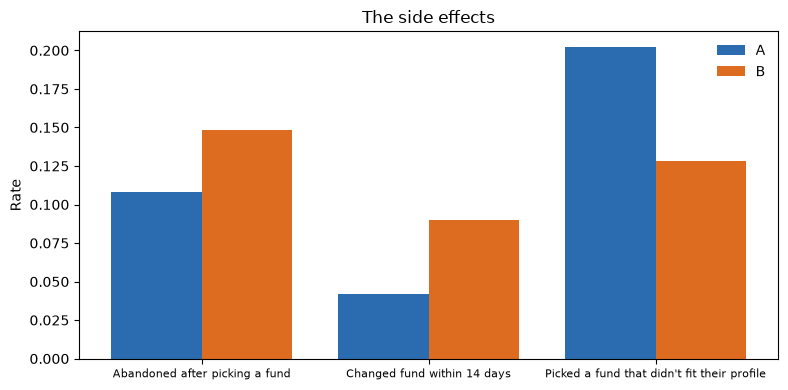

In [6]:
label = {
    "post_selection_abandonment_rate": "Abandoned after picking a fund",
    "fund_switch_regret_rate": "Changed fund within 14 days (regret)",
    "fund_profile_mismatch_rate": "Picked a fund that didn't fit their profile",
}
g = guard_df.copy()
g.index = g.index.map({"A": "A (control)", "B": "B (quiz)"})
display((g.rename(columns=label).T * 100).round(1))

plt.figure(figsize=(8, 4))
keys = list(label)
x = np.arange(len(keys))
plt.bar(x - 0.2, [guard_df.loc["A", k] for k in keys], 0.4, label="A", color=az.BLUE)
plt.bar(x + 0.2, [guard_df.loc["B", k] for k in keys], 0.4, label="B", color=az.ORANGE)
plt.xticks(x, [label[k].split(" (")[0] for k in keys], fontsize=8)
plt.ylabel("Rate")
plt.title("The side effects")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

**What this tells us — the twist.** B nearly **doubles** the rate at which people
change their fund later (from about 4% to 9%). That's a real cost to trust.

But look at the third bar: B actually makes people's *fund choice fit their
profile better*. So the problem isn't a bad recommendation — it's **speed**. The
quiz removes friction, so people commit before they've fully thought it through,
then second-guess. The fix therefore isn't "improve the recommendation"; it's
"add a moment of reassurance before confirming."

This is the bit a conversion-only analysis would miss entirely.

## Step 6 — What it's worth (in money)

Finally, we translate the improvement into commercial value, using a clearly
documented revenue assumption (see `assumptions.md`).

In [7]:
commercial = az.commercial_model(
    {"A": arm_a, "B": arm_b},
    {
        "converters": int(comm.loc["A", "converters"]),
        "converters_with_balance": int(comm.loc["A", "converters_with_balance"]),
        "mean_transfer_balance_nzd": float(comm.loc["A", "mean_transfer_balance_nzd"]),
    },
)
print(f"Extra members per year:      ~{commercial['incremental_members_annual']:,.0f}")
print(f"First-year revenue (full):   ~${commercial['first_year_revenue_full_rollout_nzd']:,.0f}")
print(f"5-year value (full rollout): ~${commercial['npv5_full_rollout_nzd']:,.0f}")
print(f"5-year value (staged 25%):   ~${commercial['npv5_staged_25pct_nzd']:,.0f}")

Extra members per year:      ~17,259
First-year revenue (full):   ~$2,282,687
5-year value (full rollout): ~$8,706,574
5-year value (staged 25%):   ~$2,176,643


## The recommendation

The numbers say B is a near-certain win worth millions. So why not launch it to
everyone immediately? Because of the regret side effect — launching everywhere at
once would lock in a real cost to trust that we haven't fixed yet.

**So the recommendation is:** roll it out to a **quarter of people first**, add a
small reassurance step at the confirmation screen, watch the regret number, and
then decide on going wider. Capture most of the upside while protecting the trust
we've earned.

**The one-sentence version for a leader:** *"The quiz lifts sign-ups by about 3
points and is almost certainly better, but it doubles the rate of second-guessing
— so I'd stage the launch and fix that first, not ship it everywhere."*

### Honest limits

The data is synthetic, so this proves the *method*, not a real business result.
It's New Zealand only, and the guardrail checks are measured on fewer people than
the main number (so they're less precise). Full details in `assumptions.md`.